# Part 1 Dataset · Open Food Facts Products export — EDA and Nutrition Extraction

This notebook is a reproducible EDA and prototype companion to the package in this repository. It analyzes the **Open Food Facts Products export** downloaded as a bounded enriched sample. **All dataset findings are computed from the downloaded export when cells run; no statistics are prefilled or fabricated.** The public export changes over time, so this notebook records the URL, sample limit, acquisition date at runtime, selected schema, and random seed. A top-of-file 50,000-row sample is a baseline, not a representative random sample of all products.

## Sections
1. Environment setup and reproducibility
2. Dataset acquisition and schema inspection
3. Loading and quick profiling
4. Missing values and duplicate analysis
5. Nutritional attribute distributions
6. Correlations, outliers, and inconsistencies
7. Image availability and metadata analysis
8. Image resolution and quality assessment
9. Image-text alignment and label suitability
10. Usable image-label pair identification
11. Dataset splitting and ML readiness assessment
12. Data preprocessing and feature engineering
13. PyTorch Dataset and DataLoader construction
14. OCR baseline: text extraction and post-processing
15. Entity tagging and nutritional value parsing
16. Unit normalization and structured JSON schema
17. Training pipeline for trainable extractor
18. Inference pipeline and structured output generation
19. Evaluation metrics and error analysis
20. Approach comparison: OCR vs. document understanding vs. VLM

> **Ground-truth warning:** Open Food Facts nutrition fields are product-level metadata, not verified transcription of a specific photograph. A product may have multiple views, stale metadata, localization differences, or no nutrition-panel image. Only human-reviewed image-grounded annotations should be used for supervised training and final evaluation. Image downloads and large model weights are intentionally bounded/opt-in.

In [43]:
# 1. Environment setup and reproducibility
# Create/activate the project venv before opening this notebook, then install: pip install -e ".[test,image-audit]"
# OCR and model-training extras are optional; this notebook does not download model weights.
from __future__ import annotations

import importlib.metadata as metadata
import json
import logging
import random
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image, ImageStat

try:
    import cv2
except ImportError:
    cv2 = None
try:
    import torch
    from torch.utils.data import DataLoader
except ImportError:
    torch = None
    DataLoader = None

ROOT = Path.cwd()
if not (ROOT / "src" / "nutrition_extraction").exists() and (ROOT / "nutrition_extraction_solution" / "src").exists():
    ROOT = ROOT / "nutrition_extraction_solution"
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
if torch is not None:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
LOGGER = logging.getLogger("nutrition_eda")
print({name: metadata.version(name) for name in ["pandas", "numpy", "Pillow", "matplotlib", "seaborn"]})
print("Python:", sys.version.split()[0], "| CPU-only workflow:", torch is None or not torch.cuda.is_available(), "| OpenCV available:", cv2 is not None)
print("Project root:", ROOT.resolve())

{'pandas': '2.3.3', 'numpy': '2.5.4', 'Pillow': '11.3.0', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}
Python: 3.12.10 | CPU-only workflow: True | OpenCV available: True
Project root: C:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution


In [44]:
# 2. Configuration; 3. Dataset acquisition and schema inspection
import yaml

CONFIG_PATH = ROOT / "configs" / "base.yaml"
CONFIG = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8")) if CONFIG_PATH.exists() else {}
DATA_PATH = ROOT / CONFIG.get("data", {}).get("source_export", "data/openfoodfacts_sample.csv")
REPORT_DIR = ROOT / "reports" / "eda"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_URL = "https://static.openfoodfacts.org/data/en.openfoodfacts.org.products.csv.gz"
SAMPLE_ROWS = int(CONFIG.get("eda", {}).get("acquisition_rows", 50_000))

# The project acquisition module chooses available nutrition/image fields dynamically.
from nutrition_extraction.acquire import acquire_sample
if not DATA_PATH.exists():
    LOGGER.info("Sample is missing; downloading up to %s rows from Open Food Facts.", SAMPLE_ROWS)
    df = acquire_sample(SOURCE_URL, DATA_PATH, row_limit=SAMPLE_ROWS)
else:
    LOGGER.info("Loading cached dataset sample: %s", DATA_PATH)
    df = pd.read_csv(DATA_PATH, low_memory=False)

acquired_at_utc = datetime.now(timezone.utc).isoformat()
schema = pd.DataFrame({"column": df.columns.astype(str), "dtype": df.dtypes.astype(str).values})
print(f"Acquired/read at UTC: {acquired_at_utc}")
print(f"Source: {SOURCE_URL}\nRows: {len(df):,}; columns: {df.shape[1]:,}; file: {DATA_PATH}")
display(schema)
print("Key columns present:", [c for c in ["code", "product_name", "brands", "categories", "ingredients_text", "image_url", "image_nutrition_url"] if c in df])
display(df.head(5))

2026-10-28 22:32:18,412 INFO Loading cached dataset sample: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\openfoodfacts_eda_enriched.csv


Acquired/read at UTC: 2026-10-28T17:02:18.883858+00:00
Source: https://static.openfoodfacts.org/data/en.openfoodfacts.org.products.csv.gz
Rows: 50,000; columns: 44; file: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\openfoodfacts_eda_enriched.csv


,column,dtype
0,code,int64
1,product_name,object
2,generic_name,object
3,quantity,object
4,brands,object
5,categories,object
6,countries,object
7,ingredients_text,object
8,serving_size,object
9,last_image_t,float64


Key columns present: ['code', 'product_name', 'brands', 'categories', 'ingredients_text', 'image_url', 'image_nutrition_url']


,code,product_name,generic_name,quantity,brands,categories,countries,ingredients_text,serving_size,last_image_t,...,vitamin-c_100g,vitamin-b1_100g,vitamin-b2_100g,vitamin-pp_100g,vitamin-b6_100g,vitamin-b9_100g,vitamin-b12_100g,potassium_100g,calcium_100g,iron_100g
0,101209159,Véritable pâte à tartiner noisettes chocolat noir,NaN,350 g,Bovetti,NaN,NaN,"HAZELNUTS, 73% cocoa dark chocolate (cocoa mas...",NaN,1.579375e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,105000011,Chamomile Herbal Tea,NaN,1 g,Lagg's,NaN,United States,CHAMOMILE FLOWERS.,1g,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,105000042,"Lagg's, herbal tea, peppermint",NaN,NaN,Lagg's,"Plant-based foods and beverages, Beverages, Ho...",United States,Peppermint.,1.61 ONZ (45 g),NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,NaN,NaN
3,105000059,Linden Flowers Tea,NaN,1.5 g,Lagg's,"Beverages and beverages preparations, Plant-ba...",United States,LINDEN FLOWERS.,1.5g,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,105000073,"Herbal Tea, Hibiscus",NaN,NaN,Lagg's,NaN,NaN,Hibiscus flowers.,1.5 g,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Raw Part 1 data preview

This section displays the downloaded Part 1 CSV exactly as stored, before the EDA transformations. It reads only the first 10 rows, preserves every field as text (including leading zeros and empty strings), and does not modify the source file.

In [45]:
# Read the persisted source sample independently so later EDA edits cannot affect this preview.
raw_part1_preview = pd.read_csv(
    DATA_PATH,
    dtype="string",
    keep_default_na=False,
    nrows=10,
)
print(f"Source file: {DATA_PATH}")
print("Preview: first 5 of up to 10 downloaded rows; source values preserved as CSV text.")
display(raw_part1_preview.head(5))

Source file: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\openfoodfacts_eda_enriched.csv
Preview: first 5 of up to 10 downloaded rows; source values preserved as CSV text.


,code,product_name,generic_name,quantity,brands,categories,countries,ingredients_text,serving_size,last_image_t,...,vitamin-c_100g,vitamin-b1_100g,vitamin-b2_100g,vitamin-pp_100g,vitamin-b6_100g,vitamin-b9_100g,vitamin-b12_100g,potassium_100g,calcium_100g,iron_100g
0,101209159,Véritable pâte à tartiner noisettes chocolat noir,,350 g,Bovetti,,,"HAZELNUTS, 73% cocoa dark chocolate (cocoa mas...",,1579374831.0,...,,,,,,,,,,
1,105000011,Chamomile Herbal Tea,,1 g,Lagg's,,United States,CHAMOMILE FLOWERS.,1g,,...,,,,,,,,,,
2,105000042,"Lagg's, herbal tea, peppermint",,,Lagg's,"Plant-based foods and beverages, Beverages, Ho...",United States,Peppermint.,1.61 ONZ (45 g),,...,,,,,,,,0.02,,
3,105000059,Linden Flowers Tea,,1.5 g,Lagg's,"Beverages and beverages preparations, Plant-ba...",United States,LINDEN FLOWERS.,1.5g,,...,,,,,,,,,,
4,105000073,"Herbal Tea, Hibiscus",,,Lagg's,,,Hibiscus flowers.,1.5 g,,...,,,,,,,,,,


In [29]:
# Keep the already bounded acquisition sample intact; it includes serving/country metadata.
from nutrition_extraction.eda import select_off_columns
SOURCE_SCHEMA_PATH = ROOT / "data" / "openfoodfacts_source_schema.json"
if SOURCE_SCHEMA_PATH.exists():
    raw_source_header = json.loads(SOURCE_SCHEMA_PATH.read_text(encoding="utf-8")).get("columns", [])
else:
    raw_source_header = df.columns.astype(str).tolist()
    LOGGER.warning("Source-header cache absent; using cached sample header.")
selected_from_schema = select_off_columns(raw_source_header)
selected_columns = [column for column in df.columns.astype(str) if column in selected_from_schema or column in {"last_image_t", "last_image_datetime", "image_small_url", "image_ingredients_small_url", "image_nutrition_small_url"}]
# The acquisition module already applies a bounded column list. Do not drop useful context fields here.
print(f"Source schema: {len(raw_source_header)} columns | cached enriched sample: {len(df.columns)} columns | task-selected intersection: {len(selected_columns)}")
print("Country/serving context retained:", [column for column in ["countries", "quantity", "serving_size", "generic_name"] if column in df.columns])
print("Sample columns:", list(df.columns))

Source schema: 211 columns | cached enriched sample: 44 columns | task-selected intersection: 39
Country/serving context retained: ['countries', 'quantity', 'serving_size', 'generic_name']
Sample columns: ['code', 'product_name', 'generic_name', 'quantity', 'brands', 'categories', 'countries', 'ingredients_text', 'serving_size', 'last_image_t', 'last_image_datetime', 'image_url', 'image_small_url', 'image_ingredients_url', 'image_ingredients_small_url', 'image_nutrition_url', 'image_nutrition_small_url', 'energy-kj_100g', 'energy-kcal_100g', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-d_100g', 'vitamin-e_100g', 'vitamin-k_100g', 'vitamin-c_100g', 'vitamin-b1_100g', 'vitamin-b2_100g', 'vitamin-pp_100g', 'vitamin-b6_100g', 'vitamin-b9_100g', 'vitamin-b12_100g', 'potassium_100g', 'calcium_100g', 'iron_100g']


## Column selection rationale and exclusions

This analysis now uses the refreshed **enriched 50,000-row sample** at `data/openfoodfacts_eda_enriched.csv`. The current sample retains 44 fields selected from the 211-column source schema: product identifiers and context (`code`, name, generic name, quantity, brands, categories, countries, ingredients, serving size), available primary and small image references, and the nutrient fields needed for coverage/distribution analysis. The exact available fields and dtypes are shown in the schema table above.

Selection is task-driven, not statistical feature selection. We retain product identity/context for image matching and subgroup checks, image URLs for candidate selection and a bounded audit, serving/country fields for locale and basis analysis, and structured nutrient fields as comparison targets. Small-image URLs are retained in the enriched source sample for audit alternatives, although primary nutrition-image URLs are preferred. We omit the remaining fields to constrain memory and focus the initial assessment: provenance/audit fields, duplicate localized/tag taxonomies, packaging and sourcing metadata, allergens/additives, derived scores, and nutrient subcomponents outside the initial target vocabulary. Many omitted fields may become useful for other questions.

The notebook computes the current exact excluded-column inventory and reasons from the cached 211-field source header; it writes `reports/eda/excluded_source_columns.csv`. The prior 47-column sample remains available as `data/openfoodfacts_sample.csv` for comparison. It is not the active sample for the updated country/serving analysis.

In [30]:
# Show all excluded source fields with an explicit, reviewable reason category.
import re

included_for_eda = set(df.columns.astype(str))
excluded_fields = sorted(set(raw_source_header) - included_for_eda)

def exclusion_category(column: str) -> tuple[str, str]:
    name = column.casefold()
    if name.startswith("image_") and ("small" in name or name.endswith("_small_url")):
        return "Redundant image derivative", "Small thumbnail duplicates the main image reference; retained the primary URL for the bounded audit."
    if name in {"created_t", "created_datetime", "last_modified_t", "last_modified_datetime", "last_modified_by", "last_updated_t", "last_updated_datetime", "creator", "owner", "url"}:
        return "Administrative / provenance", "Not required for first-pass image-to-nutrient coverage; retain for data lineage or temporal analyses."
    if name.endswith(("_tags", "_en", "_fr", "_de", "_es")) or name in {"brands_tags", "categories_tags", "countries_tags"}:
        return "Alternate taxonomy / localization", "Often a normalized, translated, or tag representation of a retained human-readable field; useful for multilingual or category-stratified studies."
    if any(term in name for term in ("packaging", "origin", "manufacturing", "emb_code", "purchase_place", "store", "city", "geo")):
        return "Packaging / sourcing / geography", "Not required for this narrow extraction baseline; geography may be useful for locale and label-format stratification."
    if any(term in name for term in ("allergen", "trace", "additive", "ingredient")):
        return "Ingredients / allergen metadata", "Outside nutrition-table entity extraction; keep if the task expands to ingredient or allergen recognition."
    if any(term in name for term in ("nutriscore", "nova", "environmental_score", "nutrient_levels", "carbon-footprint")):
        return "Derived score / sustainability", "Derived outcome or separate domain, not a raw nutrient-panel entity target in this baseline."
    if any(term in name for term in ("state", "quality", "completeness", "popularity", "scan", "no_nutrition_data")):
        return "Record quality / usage metadata", "Useful for quality filtering and bias analysis, but omitted from the first compact feature set; consider adding for a fuller audit."
    if re.search(r"_(100g|100ml)$", name):
        return "Specialist nutrient / outside initial vocabulary", "Nutrient-like field outside the selected core regex/vocabulary; review coverage before excluding it in future work."
    if name in {"generic_name", "quantity", "serving_size", "serving_quantity", "nutrition_data_per", "countries", "countries_en", "countries_tags"}:
        return "Useful product / serving context omitted", "Should be retained for locale, product identity, serving-size, or per-100g vs per-serving analyses; excluded only in the initial narrow cut."
    return "Other product metadata", "Not directly needed for the first-pass extraction target; inspect if it supports a planned split, subgroup analysis, or quality filter."

exclusion_rows = [
    {"column": column, "category": exclusion_category(column)[0], "reason": exclusion_category(column)[1]}
    for column in excluded_fields
]
excluded_columns_df = pd.DataFrame(exclusion_rows)
print(f"Source schema: {len(raw_source_header)} fields | retained in this cached EDA sample: {len(included_for_eda)} | omitted: {len(excluded_fields)}")
display(excluded_columns_df.groupby("category").agg(count=("column", "size"), examples=("column", lambda values: ", ".join(values.head(8)))).sort_values("count", ascending=False))
print("Particularly useful omitted context fields:", [name for name in ["countries", "serving_size", "serving_quantity", "nutrition_data_per", "quantity", "generic_name", "image_nutrition_small_url"] if name in excluded_fields])
excluded_report_path = REPORT_DIR / "excluded_source_columns.csv"
excluded_columns_df.to_csv(excluded_report_path, index=False)
print("Full excluded-column inventory written to:", excluded_report_path)

Source schema: 211 fields | retained in this cached EDA sample: 44 | omitted: 167


,count,examples
category,,
Specialist nutrient / outside initial vocabulary,95,"acidity_100g, added-salt_100g, added-sugars_10..."
Alternate taxonomy / localization,30,"additives_en, additives_tags, allergens_en, br..."
Administrative / provenance,10,"created_datetime, created_t, creator, last_mod..."
Other product metadata,9,"abbreviated_product_name, brand_owner, cities,..."
Packaging / sourcing / geography,8,"emb_codes, first_packaging_code_geo, manufactu..."
Derived score / sustainability,6,"carbon-footprint_100g, environmental_score_gra..."
Ingredients / allergen metadata,4,"additives, additives_n, allergens, traces"
Record quality / usage metadata,4,"completeness, no_nutrition_data, states, uniqu..."
Useful product / serving context omitted,1,serving_quantity


Particularly useful omitted context fields: ['serving_quantity']
Full excluded-column inventory written to: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\eda\excluded_source_columns.csv


In [22]:
# Cache the upstream header locally so repeat EDA runs do not re-download the remote schema.
SOURCE_SCHEMA_PATH = ROOT / "data" / "openfoodfacts_source_schema.json"
SOURCE_SCHEMA_PATH.parent.mkdir(parents=True, exist_ok=True)
if "raw_source_header" in globals() and raw_source_header:
    SOURCE_SCHEMA_PATH.write_text(json.dumps({"source_url": SOURCE_URL, "columns": raw_source_header}, indent=2), encoding="utf-8")
print("Source schema cache:", SOURCE_SCHEMA_PATH, "| exists:", SOURCE_SCHEMA_PATH.exists())

Source schema cache: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\openfoodfacts_source_schema.json | exists: True


Dataset summary (computed from this sample):
{
  "rows_examined": 50000,
  "columns_examined": 44,
  "nutrition_columns_detected": [
    "energy-kj_100g",
    "energy-kcal_100g",
    "energy_100g",
    "fat_100g",
    "saturated-fat_100g",
    "trans-fat_100g",
    "cholesterol_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g",
    "vitamin-a_100g",
    "vitamin-d_100g",
    "vitamin-e_100g",
    "vitamin-k_100g",
    "vitamin-c_100g",
    "vitamin-b1_100g",
    "vitamin-b2_100g",
    "vitamin-pp_100g",
    "vitamin-b6_100g",
    "vitamin-b9_100g",
    "vitamin-b12_100g",
    "calcium_100g",
    "iron_100g"
  ],
  "image_columns_detected": [
    "image_url",
    "image_small_url",
    "image_ingredients_url",
    "image_ingredients_small_url",
    "image_nutrition_url",
    "image_nutrition_small_url"
  ],
  "identifier_column": "code",
  "duplicate_identifier_rows": 0,
  "columns": [
    "code",
    "product_n

,column,missing_count,missing_fraction
2,generic_name,48806,0.97612
33,vitamin-k_100g,46471,0.92942
40,vitamin-b12_100g,44914,0.89828
13,image_ingredients_url,44839,0.89678
14,image_ingredients_small_url,44839,0.89678
32,vitamin-e_100g,44749,0.89498
39,vitamin-b9_100g,44686,0.89372
38,vitamin-b6_100g,44356,0.88712
36,vitamin-b2_100g,43357,0.86714
35,vitamin-b1_100g,43246,0.86492



Nutrition field coverage:


,field,non_missing_count,coverage_fraction
2,energy_100g,47759,0.95518
1,energy-kcal_100g,47748,0.95496
3,fat_100g,47704,0.95408
7,carbohydrates_100g,47687,0.95374
10,proteins_100g,47685,0.95370
11,salt_100g,47293,0.94586
12,sodium_100g,47293,0.94586
8,sugars_100g,45681,0.91362
4,saturated-fat_100g,42428,0.84856
9,fiber_100g,39535,0.79070



Numeric nutrition statistics / IQR flags:


,field,valid_numeric_count,mean,std,min,p01,median,p99,max,negative_count,iqr_outlier_count
0,energy_100g,47759,2434.831661,4944.152143,0.000000e+00,0.0,1.350000e+03,23200.000000,680000.000000,0,5548
1,energy-kcal_100g,47748,577.997612,973.414784,0.000000e+00,0.0,3.210000e+02,5515.300000,47000.000000,0,5653
2,fat_100g,47704,50.897294,4579.051485,0.000000e+00,0.0,4.080000e+00,561.000000,1000000.000000,0,6108
3,carbohydrates_100g,47687,67.613127,217.557469,0.000000e+00,0.0,2.550000e+01,625.000000,40000.000000,0,4938
4,proteins_100g,47685,13.131889,34.099017,-1.260000e+01,0.0,4.580000e+00,113.389565,1430.000000,1,4236
5,salt_100g,47293,1.089041,29.458680,0.000000e+00,0.0,6.670000e-03,10.000000,4980.000000,0,5633
6,sodium_100g,47293,0.465276,12.503303,0.000000e+00,0.0,2.890000e-03,4.062160,1990.000000,0,5388
7,sugars_100g,45681,33.576293,203.629166,0.000000e+00,0.0,7.030000e+00,408.000000,40000.000000,0,5214
8,saturated-fat_100g,42428,10.392806,29.672661,0.000000e+00,0.0,1.220000e+00,102.000000,1200.000000,0,4625
9,fiber_100g,39535,5.220936,16.637416,-4.470000e+01,0.0,1.321911e+00,50.700000,900.000000,1,5173


Quality counts: {'exact_duplicate_rows': 0, 'duplicate_product_id_rows': 0, 'unique_product_ids': 50000, 'blank_product_names': 261}


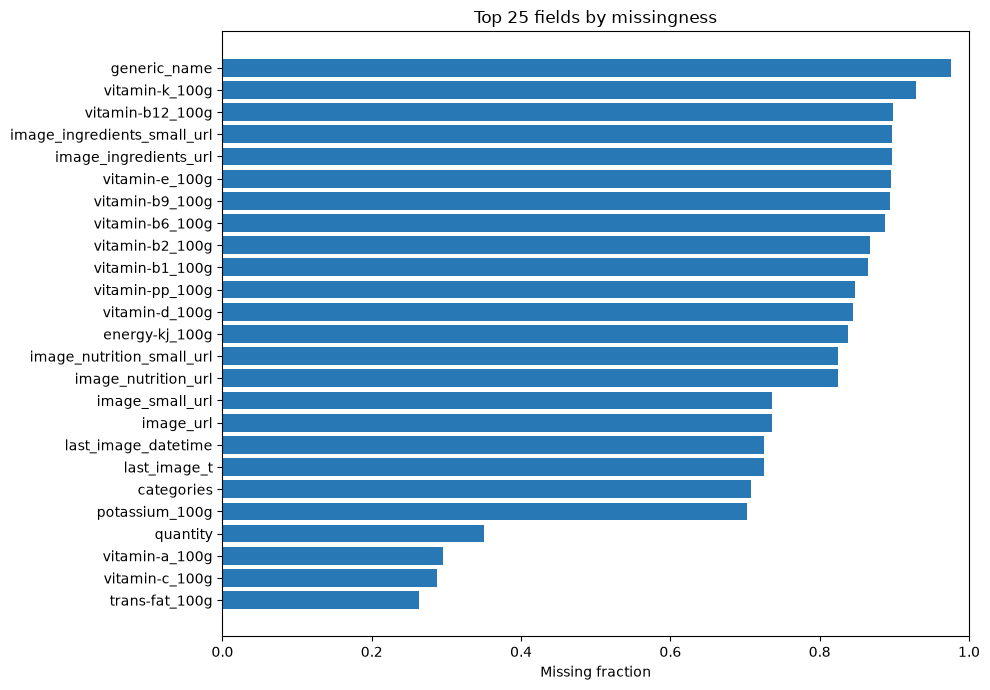

In [31]:
# 4. Loading and quick profiling; 5. Missing values, duplicates, and data quality
from nutrition_extraction.eda import analyze_export, nutrition_statistics

eda_summary, missingness, nutrition_coverage = analyze_export(df)
nutrition_cols = nutrition_coverage["field"].tolist() if not nutrition_coverage.empty else []
nutrition_stats = nutrition_statistics(df, nutrition_cols)

print("Dataset summary (computed from this sample):")
print(json.dumps(eda_summary, indent=2, default=str)[:12000])
print("\nHighest missingness fields:")
display(missingness.head(30))
print("\nNutrition field coverage:")
display(nutrition_coverage)
print("\nNumeric nutrition statistics / IQR flags:")
display(nutrition_stats)

id_col = "code" if "code" in df else None
quality_summary = {
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "duplicate_product_id_rows": int(df[id_col].duplicated(keep=False).sum()) if id_col else None,
    "unique_product_ids": int(df[id_col].nunique(dropna=True)) if id_col else None,
    "blank_product_names": int((~df["product_name"].notna() | df["product_name"].astype("string").str.strip().eq("")).sum()) if "product_name" in df else None,
}
print("Quality counts:", quality_summary)

fig, ax = plt.subplots(figsize=(10, 7))
plot_data = missingness.head(25).sort_values("missing_fraction")
ax.barh(plot_data["column"], plot_data["missing_fraction"], color="#2878B5")
ax.set_xlim(0, 1)
ax.set_xlabel("Missing fraction")
ax.set_title("Top 25 fields by missingness")
plt.tight_layout()
plt.show()

In [32]:
# Data-quality correction: exclude image timestamps and treat common placeholder strings as missing.
image_cols = [c for c in df.columns if "image" in str(c).lower() and str(c).lower().endswith("_url")]
nutrition_image_cols = [c for c in image_cols if "nutrition" in str(c).lower()]
front_image_cols = [c for c in image_cols if "front" in str(c).lower()]
def nonblank(series: pd.Series) -> pd.Series:
    normalized = series.astype("string").str.strip().str.casefold()
    return series.notna() & ~normalized.isin({"", "undefined", "nan", "none", "null", "n/a", "na"})
image_presence = pd.concat([nonblank(df[c]) for c in image_cols], axis=1).any(axis=1) if image_cols else pd.Series(False, index=df.index)
nutrition_image_presence = pd.concat([nonblank(df[c]) for c in nutrition_image_cols], axis=1).any(axis=1) if nutrition_image_cols else pd.Series(False, index=df.index)
front_image_presence = pd.concat([nonblank(df[c]) for c in front_image_cols], axis=1).any(axis=1) if front_image_cols else pd.Series(False, index=df.index)
eda_summary, missingness, nutrition_coverage = analyze_export(df)
nutrition_cols = nutrition_coverage["field"].tolist() if not nutrition_coverage.empty else []
nutrition_stats = nutrition_statistics(df, nutrition_cols)
print("Corrected image URL coverage:", {"url_columns": image_cols, "any_image_rows": int(image_presence.sum()), "nutrition_image_rows": int(nutrition_image_presence.sum()), "front_image_rows": int(front_image_presence.sum())})
print("Category top values now omit placeholders:", eda_summary.get("top_categories", {}))

Corrected image URL coverage: {'url_columns': ['image_url', 'image_small_url', 'image_ingredients_url', 'image_ingredients_small_url', 'image_nutrition_url', 'image_nutrition_small_url'], 'any_image_rows': 13694, 'nutrition_image_rows': 8803, 'front_image_rows': 0}
Category top values now omit placeholders: {'Snacks': 4029, 'Plant-based foods and beverages': 3772, 'Plant-based foods': 2754, 'Sweet snacks': 2316, 'Beverages': 2186, 'Condiments': 1404, 'Cereals and potatoes': 1372, 'Groceries': 1354, 'Dairies': 1183, 'Biscuits and cakes': 1130, 'Confectioneries': 1104, 'Desserts': 1047, 'Sauces': 1032, 'Cereals and their products': 977, 'Fermented foods': 928}


In [33]:
# Reload the edited project EDA module to ensure placeholder and image-column fixes are active.
import importlib
import nutrition_extraction.eda as eda_module
eda_module = importlib.reload(eda_module)
eda_summary, missingness, nutrition_coverage = eda_module.analyze_export(df)
nutrition_cols = nutrition_coverage["field"].tolist() if not nutrition_coverage.empty else []
nutrition_stats = eda_module.nutrition_statistics(df, nutrition_cols)
print("Rows with an actual nutrition-panel image URL:", eda_summary.get("rows_with_nutrition_image"))
print("Rows with any image URL:", eda_summary.get("rows_with_any_image_field"))
print("Top categories after placeholder exclusion:", eda_summary.get("top_categories", {}))

Rows with an actual nutrition-panel image URL: 8803
Rows with any image URL: 13694
Top categories after placeholder exclusion: {'Snacks': 4029, 'Plant-based foods and beverages': 3772, 'Plant-based foods': 2754, 'Sweet snacks': 2316, 'Beverages': 2186, 'Condiments': 1404, 'Cereals and potatoes': 1372, 'Groceries': 1354, 'Dairies': 1183, 'Biscuits and cakes': 1130, 'Confectioneries': 1104, 'Desserts': 1047, 'Sauces': 1032, 'Cereals and their products': 977, 'Fermented foods': 928}


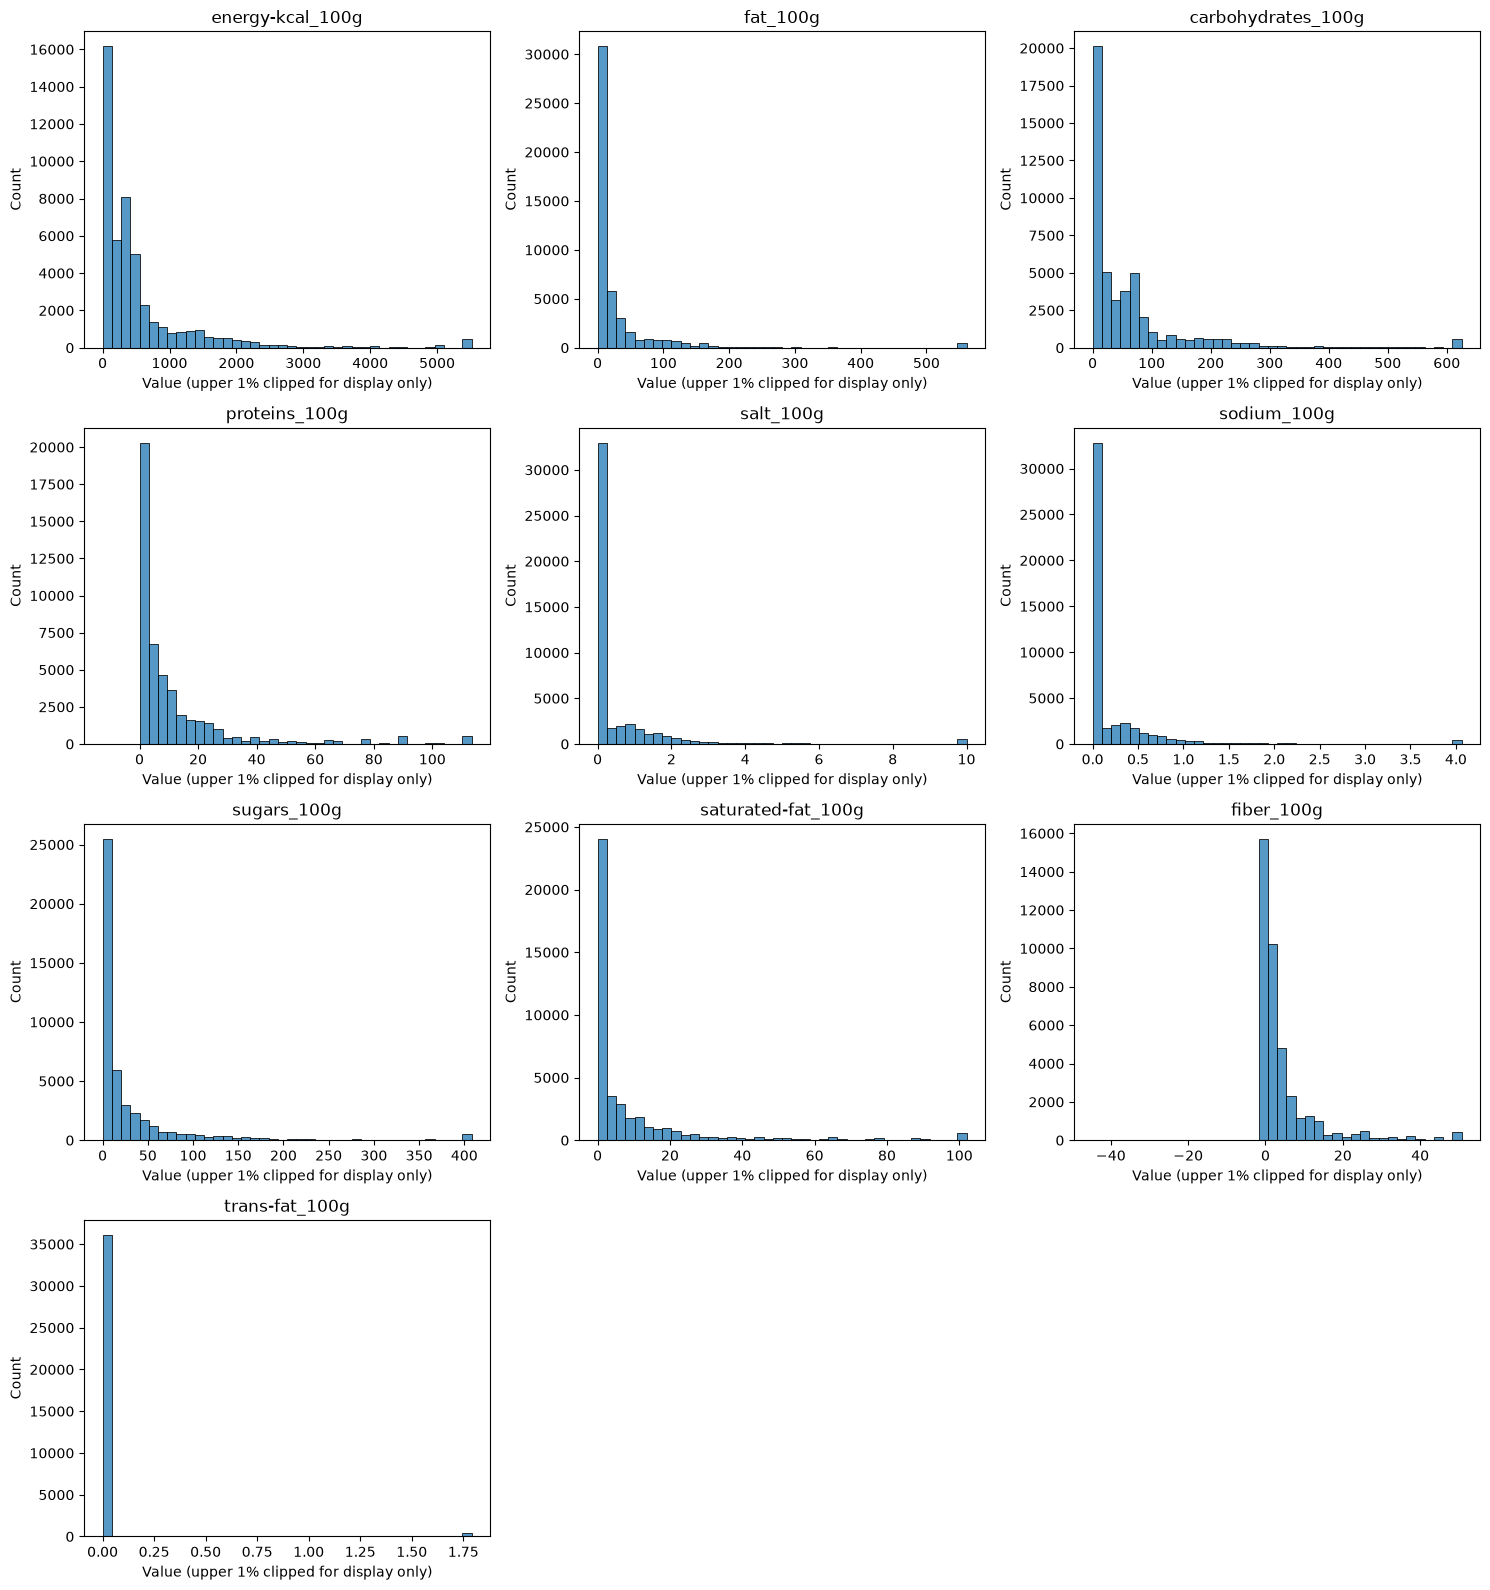

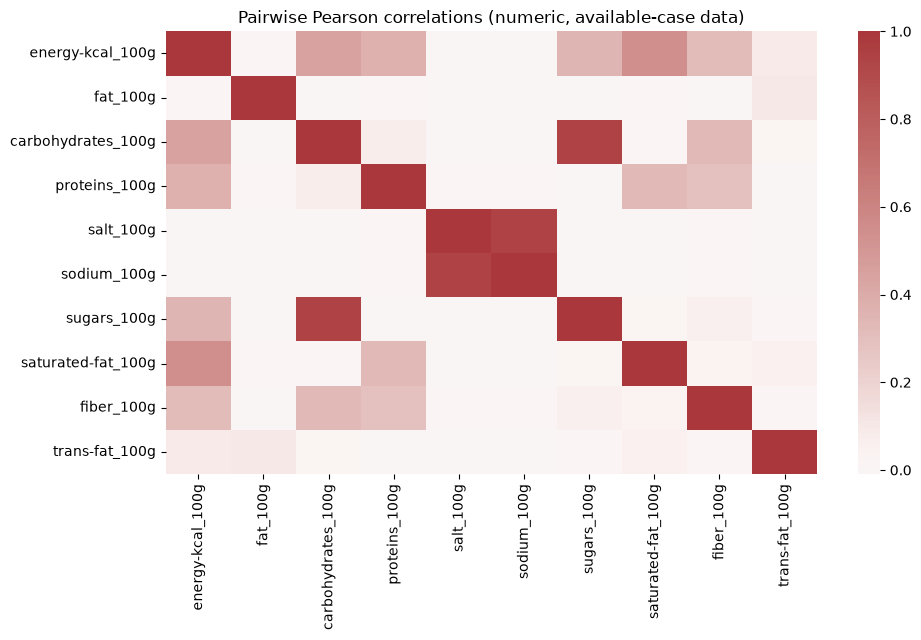

{
  "negative_values_by_field": {
    "fiber_100g": 1,
    "proteins_100g": 1
  },
  "macro_sum_over_100g_count": 16461,
  "macro_sum_over_110g_review_count": 13556,
  "note": "IQR outliers and energy outliers need contextual/manual review; energy units and serving bases vary."
}


,field,valid_numeric_count,mean,std,min,p01,median,p99,max,negative_count,iqr_outlier_count
14,vitamin-c_100g,35634,0.007540,0.164352,-7.500000e-06,0.0,0.000000e+00,0.064300,13.800000,1,7717
15,vitamin-a_100g,35204,0.022003,1.814086,-4.305331e-07,0.0,0.000000e+00,0.001071,288.600000,1,7616
10,cholesterol_100g,38374,0.044917,0.645863,-1.848640e-04,0.0,0.000000e+00,0.464487,68.000000,1,6406
2,fat_100g,47704,50.897294,4579.051485,0.000000e+00,0.0,4.080000e+00,561.000000,1000000.000000,0,6108
12,calcium_100g,37374,0.086490,6.158801,0.000000e+00,0.0,7.790000e-05,0.714000,1171.428571,0,5696
1,energy-kcal_100g,47748,577.997612,973.414784,0.000000e+00,0.0,3.210000e+02,5515.300000,47000.000000,0,5653
5,salt_100g,47293,1.089041,29.458680,0.000000e+00,0.0,6.670000e-03,10.000000,4980.000000,0,5633
0,energy_100g,47759,2434.831661,4944.152143,0.000000e+00,0.0,1.350000e+03,23200.000000,680000.000000,0,5548
6,sodium_100g,47293,0.465276,12.503303,0.000000e+00,0.0,2.890000e-03,4.062160,1990.000000,0,5388
11,iron_100g,37989,0.055276,7.256556,0.000000e+00,0.0,3.040000e-06,0.015518,1000.000000,0,5364


In [34]:
# 6. Nutritional distributions; 7. Correlations, outliers, and inconsistencies
plot_cols = [c for c in nutrition_cols if c in df and pd.to_numeric(df[c], errors="coerce").notna().sum() > 0]
preferred = [c for c in plot_cols if any(k in str(c).lower() for k in ["energy-kcal", "fat_", "carbohydrates_", "proteins_", "sugars_", "sodium_", "fiber_", "salt_"]) ]
plot_cols = (preferred or plot_cols)[:12]

if plot_cols:
    ncols = 3
    nrows = int(np.ceil(len(plot_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, column in zip(axes, plot_cols):
        values = pd.to_numeric(df[column], errors="coerce").dropna()
        if len(values):
            sns.histplot(values.clip(upper=values.quantile(0.99)), bins=40, ax=ax)
        ax.set_title(str(column))
        ax.set_xlabel("Value (upper 1% clipped for display only)")
    for ax in axes[len(plot_cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

numeric_nutrition = df[plot_cols].apply(pd.to_numeric, errors="coerce") if plot_cols else pd.DataFrame()
if numeric_nutrition.shape[1] > 1:
    plt.figure(figsize=(max(8, len(plot_cols)), max(6, len(plot_cols) * 0.65)))
    sns.heatmap(numeric_nutrition.corr(min_periods=2), cmap="vlag", center=0, annot=False)
    plt.title("Pairwise Pearson correlations (numeric, available-case data)")
    plt.tight_layout()
    plt.show()

# Domain checks are flags for review, not automatic claims that the records are wrong.
negative_counts = (numeric_nutrition < 0).sum().sort_values(ascending=False) if not numeric_nutrition.empty else pd.Series(dtype=int)
macro_cols = [c for c in numeric_nutrition.columns if any(k in str(c).lower() for k in ["fat_100g", "carbohydrates_100g", "proteins_100g", "fiber_100g"])]
macro_sum = numeric_nutrition[macro_cols].sum(axis=1, min_count=1) if macro_cols else pd.Series(dtype=float)
quality_flags = {
    "negative_values_by_field": negative_counts[negative_counts > 0].to_dict(),
    "macro_sum_over_100g_count": int((macro_sum > 100).sum()) if len(macro_sum) else None,
    "macro_sum_over_110g_review_count": int((macro_sum > 110).sum()) if len(macro_sum) else None,
    "note": "IQR outliers and energy outliers need contextual/manual review; energy units and serving bases vary.",
}
print(json.dumps(quality_flags, indent=2, default=str))
display(nutrition_stats.sort_values("iqr_outlier_count", ascending=False) if "iqr_outlier_count" in nutrition_stats else nutrition_stats)

In [35]:
# 8. Image availability; 9. Bounded image resolution and quality audit
import io
import urllib.request

# Only URL fields count as image references; timestamps and placeholder strings are excluded.
image_cols = [c for c in df.columns if "image" in str(c).lower() and str(c).lower().endswith("_url")]
nutrition_image_cols = [c for c in image_cols if "nutrition" in str(c).lower()]
front_image_cols = [c for c in image_cols if "front" in str(c).lower()]
def nonblank(series: pd.Series) -> pd.Series:
    normalized = series.astype("string").str.strip().str.casefold()
    return series.notna() & ~normalized.isin({"", "undefined", "nan", "none", "null", "n/a", "na"})
image_presence = pd.concat([nonblank(df[c]) for c in image_cols], axis=1).any(axis=1) if image_cols else pd.Series(False, index=df.index)
nutrition_image_presence = pd.concat([nonblank(df[c]) for c in nutrition_image_cols], axis=1).any(axis=1) if nutrition_image_cols else pd.Series(False, index=df.index)
front_image_presence = pd.concat([nonblank(df[c]) for c in front_image_cols], axis=1).any(axis=1) if front_image_cols else pd.Series(False, index=df.index)
print({"image_url_columns": image_cols, "rows_with_any_image_url": int(image_presence.sum()),
       "rows_with_nutrition_image_url": int(nutrition_image_presence.sum()),
       "rows_with_front_image_url": int(front_image_presence.sum())})

# Audit at most the configured handful of images (default 10); no bulk image download.
IMAGE_AUDIT_LIMIT = int(CONFIG.get("eda", {}).get("image_audit_limit", 10))
def to_http_url(value: object) -> str | None:
    if not isinstance(value, str) or not value.strip():
        return None
    value = value.strip()
    return value if value.startswith(("http://", "https://")) else None

image_audit_rows = []
if IMAGE_AUDIT_LIMIT > 0 and image_cols:
    priority_cols = nutrition_image_cols + [c for c in image_cols if c not in nutrition_image_cols]
    candidates = df.loc[nutrition_image_presence].head(IMAGE_AUDIT_LIMIT * 4)
    for row_index, row in candidates.iterrows():
        if len(image_audit_rows) >= IMAGE_AUDIT_LIMIT:
            break
        url = next((to_http_url(row[c]) for c in priority_cols if to_http_url(row[c])), None)
        if not url:
            continue
        item = {"row_index": int(row_index), "product_id": str(row.get("code", row_index)), "image_url": url}
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "NutritionExtractionResearch/0.1"})
            with urllib.request.urlopen(request, timeout=12) as response:
                item["content_type"] = response.headers.get("Content-Type", "")
                payload = response.read(8 * 1024 * 1024 + 1)
            if len(payload) > 8 * 1024 * 1024:
                raise ValueError("image exceeded 8 MiB safety cap")
            with Image.open(io.BytesIO(payload)) as opened:
                opened.verify()
            with Image.open(io.BytesIO(payload)) as opened:
                rgb = opened.convert("RGB")
                width, height = rgb.size
                item.update({"readable": True, "width": width, "height": height,
                             "aspect_ratio": width / height if height else None,
                             "mean_brightness": float(np.asarray(rgb).mean()),
                             "pixel_std": float(np.asarray(rgb).std())})
        except Exception as error:
            item.update({"readable": False, "error": f"{type(error).__name__}: {error}"})
        image_audit_rows.append(item)
image_audit = pd.DataFrame(image_audit_rows)
if not image_audit.empty:
    display(image_audit.drop(columns=["image_url"], errors="ignore"))
    print("Audited nutrition images:", len(image_audit), "| decode success:", int(image_audit.get("readable", pd.Series(dtype=bool)).sum()))
    if "width" in image_audit:
        display(image_audit[["width", "height", "aspect_ratio", "mean_brightness", "pixel_std"]].describe())
else:
    print("Image audit skipped or no nutrition image URLs available.")

{'image_url_columns': ['image_url', 'image_small_url', 'image_ingredients_url', 'image_ingredients_small_url', 'image_nutrition_url', 'image_nutrition_small_url'], 'rows_with_any_image_url': 13694, 'rows_with_nutrition_image_url': 8803, 'rows_with_front_image_url': 0}


,row_index,product_id,content_type,readable,width,height,aspect_ratio,mean_brightness,pixel_std
0,0,101209159,image/jpeg,True,400,376,1.063830,83.906846,68.121196
1,33,241013128,image/jpeg,True,400,253,1.581028,153.438185,35.459973
2,34,247016406,image/jpeg,True,400,215,1.860465,92.213578,25.400008
3,86,630135899,image/jpeg,True,353,400,0.882500,126.867358,67.876911
4,96,653007548,image/jpeg,True,400,227,1.762115,146.322177,36.279427
5,97,672016408,image/jpeg,True,300,400,0.750000,63.215575,48.682403
6,121,790310013,image/jpeg,True,200,400,0.500000,132.858758,38.943543
7,122,790310020,image/jpeg,True,192,400,0.480000,154.393967,50.388571
8,123,790310044,image/jpeg,True,206,400,0.515000,145.262977,39.115757
9,141,790410058,image/jpeg,True,400,74,5.405405,143.834944,65.279321


Audited nutrition images: 10 | decode success: 10


,width,height,aspect_ratio,mean_brightness,pixel_std
count,10.000000,10.000000,10.000000,10.000000,10.000000
mean,325.100000,314.500000,1.480034,124.231437,47.554711
std,92.501592,115.235267,1.475657,32.545637,15.162271
min,192.000000,74.000000,0.480000,63.215575,25.400008
25%,229.500000,233.500000,0.573750,100.877023,36.945456
50%,376.500000,388.000000,0.973165,138.346851,43.899080
75%,400.000000,400.000000,1.716843,146.057377,61.556634
max,400.000000,400.000000,5.405405,154.393967,68.121196


In [37]:
# 10. Image-text alignment and label suitability; 11. Candidate pairs, splits, readiness
# Metadata agreement is only a proxy. A human must confirm exact values in each selected image.
target_terms = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g", "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g", "sodium_100g"]
target_cols = [c for c in target_terms if c in df]
label_presence = pd.concat([pd.to_numeric(df[c], errors="coerce").notna() for c in target_cols], axis=1) if target_cols else pd.DataFrame(index=df.index)
df_work = df.copy()
df_work["_has_any_image_ref"] = image_presence
# Explicit nutrition-panel reference preferred; generic images still require view verification.
df_work["_has_nutrition_image_ref"] = nutrition_image_presence
df_work["_nutrition_label_count"] = label_presence.sum(axis=1) if target_cols else 0
df_work["_has_any_nutrition_label"] = df_work["_nutrition_label_count"].gt(0)
df_work["_candidate_pair"] = df_work["_has_any_image_ref"] & df_work["_has_any_nutrition_label"]
df_work["_strict_panel_candidate"] = df_work["_has_nutrition_image_ref"] & df_work["_has_any_nutrition_label"]

manual_gold_path = ROOT / "data" / "evaluation" / "gold_records.jsonl"
manual_record_count = sum(1 for line in manual_gold_path.read_text(encoding="utf-8").splitlines() if line.strip()) if manual_gold_path.exists() else 0
alignment_summary = {
    "rows_with_any_image_and_any_structured_target_label": int(df_work["_candidate_pair"].sum()),
    "rows_with_explicit_nutrition_image_and_any_structured_target_label": int(df_work["_strict_panel_candidate"].sum()),
    "manually_reviewed_record_level_gold_examples": manual_record_count,
    "manually_verified_word_box_bio_annotations": 0,
    "warning": "Metadata pairing is not verified alignment. One record-level example is not enough for model evaluation or training.",
}
print(json.dumps(alignment_summary, indent=2))

candidate_pairs = df_work.loc[df_work["_candidate_pair"]].copy()
review_columns = [c for c in ["code", "product_name", "brands", "categories", "countries", *nutrition_image_cols, *target_cols] if c in candidate_pairs]
review_sheet = candidate_pairs[review_columns].head(500)
review_path = REPORT_DIR / "image_label_manual_review_candidates.csv"
review_sheet.to_csv(review_path, index=False)
print(f"Saved up to {len(review_sheet)} manual-review candidates to {review_path}")

# Product-group split is only provisional for the metadata candidate list, never a supervised model split.
from sklearn.model_selection import GroupShuffleSplit
split_frame = candidate_pairs.dropna(subset=["code"]).copy() if "code" in candidate_pairs else candidate_pairs.copy()
split_groups = split_frame["code"].astype(str) if "code" in split_frame else split_frame.index.astype(str)
if len(split_frame) >= 3 and pd.Series(split_groups).nunique() >= 3:
    outer = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED)
    remain_idx, test_idx = next(outer.split(split_frame, groups=split_groups))
    remain = split_frame.iloc[remain_idx]
    remain_groups = pd.Series(split_groups).iloc[remain_idx]
    inner = GroupShuffleSplit(n_splits=1, test_size=0.10 / 0.90, random_state=SEED + 1)
    train_local, valid_local = next(inner.split(remain, groups=remain_groups))
    split_sizes = {"train": len(train_local), "validation": len(valid_local), "test": len(test_idx)}
    split_groups_check = {
        "train": set(pd.Series(split_groups).iloc[remain_idx].iloc[train_local]),
        "validation": set(pd.Series(split_groups).iloc[remain_idx].iloc[valid_local]),
        "test": set(pd.Series(split_groups).iloc[test_idx]),
    }
    print("Metadata-candidate split counts (not labeled dataset):", split_sizes)
    print("No product-group overlap:", all(split_groups_check[a].isdisjoint(split_groups_check[b]) for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]))
else:
    print("Not enough candidate product groups for three-way split.")

readiness = {
    "target_nutrition_fields_found": target_cols,
    "candidate_records": int(len(candidate_pairs)),
    "strict_nutrition_panel_candidates": int(df_work["_strict_panel_candidate"].sum()),
    "manually_verified_record_level_examples": manual_record_count,
    "manually_verified_token_level_annotations": 0,
    "supervised_training_ready": False,
    "reason": "One manually verified record exists, but word boxes/BIO tags and a substantial independent gold set are still missing.",
}
print("ML readiness:", json.dumps(readiness, indent=2))

{
  "rows_with_any_image_and_any_structured_target_label": 12771,
  "rows_with_explicit_nutrition_image_and_any_structured_target_label": 8527,
  "manually_reviewed_record_level_gold_examples": 1,
  "manually_verified_word_box_bio_annotations": 0,
  "warning": "Metadata pairing is not verified alignment. One record-level example is not enough for model evaluation or training."
}
Saved up to 500 manual-review candidates to c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\eda\image_label_manual_review_candidates.csv
Metadata-candidate split counts (not labeled dataset): {'train': 10216, 'validation': 1277, 'test': 1278}
No product-group overlap: True
ML readiness: {
  "target_nutrition_fields_found": [
    "energy-kcal_100g",
    "fat_100g",
    "saturated-fat_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
  ],
  "candidate_records": 12771,
  "strict_nutrition_panel_

In [39]:
# Persist measured enriched-sample EDA artifacts and sample-specific observations.
manual_gold_path = ROOT / "data" / "evaluation" / "gold_records.jsonl"
manual_gold_count = sum(1 for line in manual_gold_path.read_text(encoding="utf-8").splitlines() if line.strip()) if manual_gold_path.exists() else 0
serving_summary = {
    column: {"non_missing": int(nonblank(df[column]).sum()), "fraction": float(nonblank(df[column]).mean())}
    for column in ["countries", "quantity", "serving_size"] if column in df
}
eda_summary.update({
    "source_url": SOURCE_URL,
    "acquired_at_utc": acquired_at_utc,
    "row_limit": SAMPLE_ROWS,
    "selection_note": "Enriched 44-column first-row sample; top-of-file, not random or globally representative.",
    "metadata_image_label_candidates": int(df_work["_candidate_pair"].sum()),
    "nutrition_image_label_candidates": int(df_work["_strict_panel_candidate"].sum()),
    "manually_reviewed_record_level_gold_examples": manual_gold_count,
    "manually_verified_token_box_bio_annotations": 0,
    "serving_locale_coverage": serving_summary,
    "supervised_training_ready": False,
})
(REPORT_DIR / "summary.json").write_text(json.dumps(eda_summary, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
missingness.to_csv(REPORT_DIR / "missingness.csv", index=False)
nutrition_coverage.to_csv(REPORT_DIR / "nutrition_coverage.csv", index=False)
nutrition_stats.to_csv(REPORT_DIR / "nutrition_statistics.csv", index=False)
(df[nutrition_cols].apply(pd.to_numeric, errors="coerce").corr(min_periods=2) if nutrition_cols else pd.DataFrame()).to_csv(REPORT_DIR / "nutrition_correlations.csv")
if "countries" in df:
    country_values = df["countries"].dropna().astype("string").str.split(",").explode().str.strip()
    country_values = country_values[~country_values.str.casefold().isin({"", "undefined", "nan", "none", "null", "n/a", "na"})]
    country_values.value_counts().rename_axis("country").reset_index(name="occurrences").to_csv(REPORT_DIR / "country_counts.csv", index=False)
if not image_audit.empty:
    image_audit.drop(columns=["image_url"], errors="ignore").to_csv(REPORT_DIR / "image_resolution_audit.csv", index=False)
review_sheet.to_csv(REPORT_DIR / "image_label_manual_review_candidates.csv", index=False)

main_targets = [c for c in ["energy-kcal_100g", "fat_100g", "carbohydrates_100g", "proteins_100g", "sugars_100g", "fiber_100g", "sodium_100g"] if c in df]
main_coverage = nutrition_coverage.set_index("field")["coverage_fraction"].to_dict() if not nutrition_coverage.empty else {}
observations = [
    f"The enriched analyzed subset contains {len(df):,} rows and {df.shape[1]} retained columns; this is the first {len(df):,} rows, not a random sample.",
    f"{int(image_presence.sum()):,} records ({image_presence.mean():.1%}) have any image URL; {int(nutrition_image_presence.sum()):,} ({nutrition_image_presence.mean():.1%}) have a nutrition-image URL.",
    f"{int(df_work['_candidate_pair'].sum()):,} are image+target metadata candidates and {int(df_work['_strict_panel_candidate'].sum()):,} have an explicit nutrition image; these are not verified pairs.",
    f"Country, quantity and serving-size coverage: {serving_summary}.",
    f"Negative values in selected targets: {quality_flags['negative_values_by_field']}; investigate extremes rather than auto-delete.",
    f"One record-level gold example was manually transcribed; word boxes/BIO labels remain at {0} and there are no aggregate model metrics.",
]
print("\nDATA-DRIVEN OBSERVATIONS (current enriched sample):")
for observation in observations:
    print("-", observation)
print("\nSaved report artifacts in:", REPORT_DIR.resolve())
print("Main nutrient coverage:", {field: main_coverage.get(field) for field in main_targets})


DATA-DRIVEN OBSERVATIONS (current enriched sample):
- The enriched analyzed subset contains 50,000 rows and 44 retained columns; this is the first 50,000 rows, not a random sample.
- 13,694 records (27.4%) have any image URL; 8,803 (17.6%) have a nutrition-image URL.
- 12,771 are image+target metadata candidates and 8,527 have an explicit nutrition image; these are not verified pairs.
- Country, quantity and serving-size coverage: {'countries': {'non_missing': 42799, 'fraction': 0.85598}, 'quantity': {'non_missing': 32493, 'fraction': 0.64986}, 'serving_size': {'non_missing': 47600, 'fraction': 0.952}}.
- Negative values in selected targets: {'fiber_100g': 1, 'proteins_100g': 1}; investigate extremes rather than auto-delete.
- One record-level gold example was manually transcribed; word boxes/BIO labels remain at 0 and there are no aggregate model metrics.

Saved report artifacts in: C:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\eda
Main 

In [11]:
# 12. Data preprocessing and feature engineering; 13. PyTorch Dataset and DataLoader
from nutrition_extraction.preprocessing import normalize_nutrient_name, normalize_ocr_text, preprocess_image
from nutrition_extraction.splitting import make_splits

# Preserve raw data, parse numerical fields explicitly, and keep malformed values measurable.
clean_df = df.copy()
for column in target_cols:
    clean_df[column + "__numeric"] = pd.to_numeric(clean_df[column], errors="coerce")
print("Missing/parse-failure rates for targets:")
display(pd.DataFrame({"field": target_cols, "parseable_fraction": [clean_df[c + "__numeric"].notna().mean() for c in target_cols]}))
print("Text normalization examples:", [normalize_ocr_text(x) for x in ["  Energy\u00a0 200 kcal ", "Proteins\n 4 g"]])
print("Nutrient alias examples:", {x: normalize_nutrient_name(x) for x in ["of which saturates", "sodium", "kcal"]})

# Document-level dataset requires OCR words + boxes + human-verified BIO tags in JSONL.
# Product-level metadata dataset below is a weak-label ingestion demo and must not be treated as gold OCR labels.
ANNOTATION_MANIFEST = ROOT / CONFIG.get("data", {}).get("annotation_manifest", "data/annotations.jsonl")
if torch is None:
    print("PyTorch is not installed in this lightweight EDA environment; install the optional [train] extra to use Dataset/DataLoader.")
else:
    from nutrition_extraction.dataset import NutritionDocumentDataset, ProductImageMetadataDataset
    print("Available datasets:", NutritionDocumentDataset.__name__, ProductImageMetadataDataset.__name__)
    if ANNOTATION_MANIFEST.exists():
        from transformers import AutoProcessor
        labels = CONFIG["model"]["labels"]
        processor = AutoProcessor.from_pretrained(CONFIG["model"]["pretrained_name"], apply_ocr=False)
        doc_dataset = NutritionDocumentDataset(ANNOTATION_MANIFEST, processor, {label: i for i, label in enumerate(labels)}, ROOT)
        doc_loader = DataLoader(doc_dataset, batch_size=2, shuffle=True, num_workers=0)
        print("Annotated batches:", len(doc_loader))
    else:
        print("No manually annotated token manifest found; no supervised DataLoader is instantiated.")

Missing/parse-failure rates for targets:


,field,parseable_fraction
0,energy-kcal_100g,0.95424
1,fat_100g,0.95336
2,saturated-fat_100g,0.84794
3,carbohydrates_100g,0.95302
4,sugars_100g,0.91294
5,fiber_100g,0.79028
6,proteins_100g,0.95298
7,salt_100g,0.94514
8,sodium_100g,0.94514


Text normalization examples: ['Energy 200 kcal', 'Proteins 4 g']
Nutrient alias examples: {'of which saturates': 'saturated_fat', 'sodium': 'sodium', 'kcal': 'energy'}
Available datasets: NutritionDocumentDataset ProductImageMetadataDataset
No manually annotated token manifest found; no supervised DataLoader is instantiated.


In [12]:
# 14. OCR baseline; 15. Entity tagging and nutritional value parsing
from nutrition_extraction.ocr import PaddleOCRBackend, TesseractBackend, load_preprocessed_image
from nutrition_extraction.extraction import associate_rows, extract_record, normalize_measurement, tag_ocr_tokens

# Set RUN_OCR_DEMO=True only after installing/configuring an OCR engine and choosing one local image.
RUN_OCR_DEMO = False
OCR_DEMO_IMAGE = ROOT / "data" / "manual_samples" / "nutrition_panel.jpg"
OCR_BACKEND_NAME = CONFIG.get("ocr", {}).get("backend", "tesseract")
if RUN_OCR_DEMO and OCR_DEMO_IMAGE.exists():
    if OCR_BACKEND_NAME == "paddleocr":
        ocr_backend = PaddleOCRBackend(language=CONFIG.get("ocr", {}).get("paddle_language", "en"))
    elif OCR_BACKEND_NAME == "tesseract":
        ocr_backend = TesseractBackend(
            executable=CONFIG.get("ocr", {}).get("tesseract_cmd"),
            language=CONFIG.get("ocr", {}).get("tesseract_language", "eng"),
        )
    else:
        raise ValueError(f"Unknown OCR backend: {OCR_BACKEND_NAME}")
    ocr_image = load_preprocessed_image(OCR_DEMO_IMAGE, CONFIG.get("ocr", {}).get("max_image_side", 2000))
    ocr_tokens = ocr_backend.extract(ocr_image)
    ocr_record = extract_record(OCR_DEMO_IMAGE.stem, ocr_tokens, str(OCR_DEMO_IMAGE))
    display(pd.DataFrame([token.__dict__ for token in ocr_tokens]))
    display(ocr_record.to_dict())
else:
    print("OCR demo is opt-in; set RUN_OCR_DEMO=True and provide a local, manually selected panel image.")
print("Supported OCR adapters: Tesseract CPU adapter (binary installed separately), PaddleOCR (optional adapter; install its Windows CPU runtime separately).")
print("Approach-A disclaimer: lexical/value parsing is a baseline; spatial pairing may be wrong for multiple columns or serving-basis tables.")

OCR demo is opt-in; set RUN_OCR_DEMO=True and provide a local, manually selected panel image.
Supported OCR adapters: Tesseract CPU adapter (binary installed separately), PaddleOCR (optional adapter; install its Windows CPU runtime separately).
Approach-A disclaimer: lexical/value parsing is a baseline; spatial pairing may be wrong for multiple columns or serving-basis tables.


In [41]:
# 16. Unit normalization and structured JSON schema; 17. Training pipeline
import importlib
import nutrition_extraction.extraction as extraction_module
extraction_module = importlib.reload(extraction_module)
from nutrition_extraction.schema import NutritionField, NutritionRecord
from nutrition_extraction.extraction import canonicalize_measurement

# Normalization preserves observed values/units while computing comparable canonical quantities.
unit_examples = [(0.5, "g"), (350, "mg"), (992, "kJ"), (1, "µg")]
normalized_examples = [canonicalize_measurement(value, unit) for value, unit in unit_examples]
print("Canonical conversions (mass -> g, volume -> ml, energy -> kcal):", normalized_examples)

NUTRITION_RECORD_JSON_SCHEMA = {
    "$schema": "https://json-schema.org/draft/2020-12/schema",
    "type": "object",
    "required": ["product_id", "fields", "needs_review", "schema_version"],
    "properties": {
        "product_id": {"type": "string"}, "source_image": {"type": ["string", "null"]},
        "needs_review": {"type": "boolean"}, "warnings": {"type": "array", "items": {"type": "string"}},
        "schema_version": {"type": "string"},
        "fields": {"type": "array", "items": {"type": "object", "required": ["nutrient", "value", "unit"], "properties": {
            "nutrient": {"type": "string"}, "value": {"type": ["number", "null"]},
            "unit": {"type": ["string", "null"]}, "basis": {"type": ["string", "null"]},
            "normalized_value": {"type": ["number", "null"]}, "normalized_unit": {"type": ["string", "null"]},
            "raw_text": {"type": ["string", "null"]}, "confidence": {"type": ["number", "null"]}}}},
    },
}
print(json.dumps(NUTRITION_RECORD_JSON_SCHEMA, indent=2))
if RUN_OCR_DEMO and "ocr_record" in globals():
    print(json.dumps(ocr_record.to_dict(), indent=2, ensure_ascii=False))

# LayoutLMv3 takes image + OCR words + normalized [0,1000] boxes + verified BIO labels.
ALLOW_PRETRAINED_WEIGHT_DOWNLOAD = False
MODEL_TRAINING_READY = torch is not None and ANNOTATION_MANIFEST.exists()
print({"layoutlmv3_ready": MODEL_TRAINING_READY, "weight_download_enabled": ALLOW_PRETRAINED_WEIGHT_DOWNLOAD,
       "train_command": "nutrition-train --config configs/base.yaml", "loss": "cross-entropy; ignore_index=-100 for special/padding tokens"})
if not ALLOW_PRETRAINED_WEIGHT_DOWNLOAD:
    print("Model construction/training is intentionally not run until weights are approved and many image-grounded annotations exist.")

Canonical conversions (mass -> g, volume -> ml, energy -> kcal): [(0.5, 'g'), (0.35, 'g'), (237.09369024856596, 'kcal'), (1e-06, 'g')]
{
  "$schema": "https://json-schema.org/draft/2020-12/schema",
  "type": "object",
  "required": [
    "product_id",
    "fields",
    "needs_review",
    "schema_version"
  ],
  "properties": {
    "product_id": {
      "type": "string"
    },
    "source_image": {
      "type": [
        "string",
        "null"
      ]
    },
    "needs_review": {
      "type": "boolean"
    },
    "warnings": {
      "type": "array",
      "items": {
        "type": "string"
      }
    },
    "schema_version": {
      "type": "string"
    },
    "fields": {
      "type": "array",
      "items": {
        "type": "object",
        "required": [
          "nutrient",
          "value",
          "unit"
        ],
        "properties": {
          "nutrient": {
            "type": "string"
          },
          "value": {
            "type": [
              "number",

OCR baseline entrypoint: nutrition-ocr-predict --config configs/base.yaml --image data/manual_samples/241013128_nutrition.jpg --output reports/prediction.json
Layout-aware model entrypoint: nutrition-predict --config configs/base.yaml --checkpoint artifacts/model --image data/manual_samples/241013128_nutrition.jpg --output reports/layoutlm_prediction.json
Evaluation entrypoint: nutrition-evaluate --config configs/base.yaml --checkpoint artifacts/model
One manually verified record-level gold example exists; OCR/model prediction file is not present, so no real score is reported.
Manual OCR transcription exists, but no OCR output exists yet; CER/WER are pending.
Error analysis template: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\eda\error_analysis_template.csv


,approach,compute,strength,risk
0,A. OCR + rules,Low CPU; OCR engine required,Transparent baseline and confidence/geometry,OCR errors and heuristic table row association
1,B. LayoutLMv3 token tagging,CPU training slow; pretrained weights needed,Joint text/image/layout features,Needs many verified word-box BIO labels
2,C. Open-weight VLM,Varies; many models too large for CPU,Can interpret visual context directly,"Hallucination, memory, latency, license, JSON ..."


Compare on the same held-out annotated products; report quality, latency, abstention and resource use.


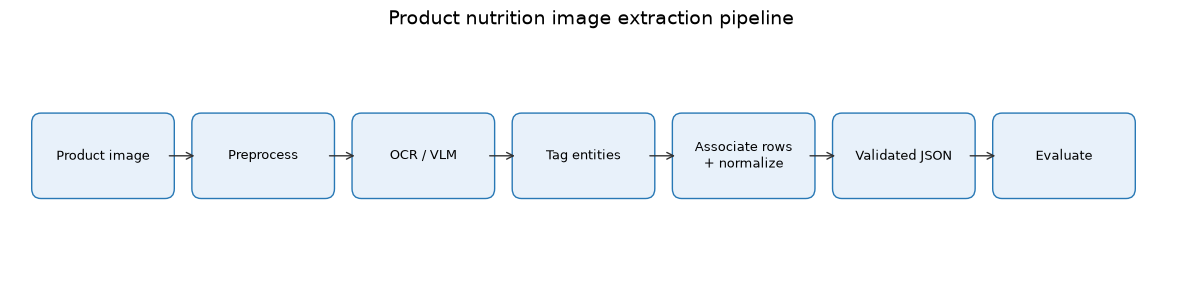

In [42]:
# 18. Inference; 19. Metrics and error analysis; 20. Approach comparison and architecture
from nutrition_extraction.evaluation import character_error_rate, entity_prf, measure_latency, structured_metrics, word_error_rate

print("OCR baseline entrypoint:", "nutrition-ocr-predict --config configs/base.yaml --image data/manual_samples/241013128_nutrition.jpg --output reports/prediction.json")
print("Layout-aware model entrypoint:", "nutrition-predict --config configs/base.yaml --checkpoint artifacts/model --image data/manual_samples/241013128_nutrition.jpg --output reports/layoutlm_prediction.json")
print("Evaluation entrypoint:", "nutrition-evaluate --config configs/base.yaml --checkpoint artifacts/model")

GOLD_JSONL = ROOT / "data" / "evaluation" / "gold_records.jsonl"
PRED_JSONL = ROOT / "data" / "evaluation" / "predicted_records.jsonl"
if GOLD_JSONL.exists() and PRED_JSONL.exists():
    from nutrition_extraction.schema import NutritionRecord
    gold_records = [NutritionRecord.from_dict(json.loads(line)) for line in GOLD_JSONL.read_text(encoding="utf-8").splitlines() if line.strip()]
    predicted_records = [NutritionRecord.from_dict(json.loads(line)) for line in PRED_JSONL.read_text(encoding="utf-8").splitlines() if line.strip()]
    display(pd.Series(structured_metrics(gold_records, predicted_records), name="evaluation"))
elif GOLD_JSONL.exists():
    print("One manually verified record-level gold example exists; OCR/model prediction file is not present, so no real score is reported.")
else:
    print("No manually verified gold records found; no extraction score is reported.")

GOLD_TRANSCRIPTION = ROOT / "data" / "evaluation" / "gold_ocr.txt"
PRED_TRANSCRIPTION = ROOT / "data" / "evaluation" / "predicted_ocr.txt"
if GOLD_TRANSCRIPTION.exists() and PRED_TRANSCRIPTION.exists():
    reference, hypothesis = GOLD_TRANSCRIPTION.read_text(encoding="utf-8"), PRED_TRANSCRIPTION.read_text(encoding="utf-8")
    print({"CER": character_error_rate(reference, hypothesis), "WER": word_error_rate(reference, hypothesis)})
elif GOLD_TRANSCRIPTION.exists():
    print("Manual OCR transcription exists, but no OCR output exists yet; CER/WER are pending.")

error_log_path = REPORT_DIR / "error_analysis_template.csv"
if not error_log_path.exists():
    pd.DataFrame(columns=["product_id", "image_path", "failure_category", "gold_text", "predicted_text", "root_cause", "severity", "corrective_action"]).to_csv(error_log_path, index=False)
print("Error analysis template:", error_log_path)

comparison = pd.DataFrame([
    {"approach": "A. OCR + rules", "compute": "Low CPU; OCR engine required", "strength": "Transparent baseline and confidence/geometry", "risk": "OCR errors and heuristic table row association"},
    {"approach": "B. LayoutLMv3 token tagging", "compute": "CPU training slow; pretrained weights needed", "strength": "Joint text/image/layout features", "risk": "Needs many verified word-box BIO labels"},
    {"approach": "C. Open-weight VLM", "compute": "Varies; many models too large for CPU", "strength": "Can interpret visual context directly", "risk": "Hallucination, memory, latency, license, JSON reliability"},
])
display(comparison)
print("Compare on the same held-out annotated products; report quality, latency, abstention and resource use.")

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(15, 3.2))
ax.set_xlim(0, 15); ax.set_ylim(0, 3); ax.axis("off")
flow_nodes = ["Product image", "Preprocess", "OCR / VLM", "Tag entities", "Associate rows\n+ normalize", "Validated JSON", "Evaluate"]
xs = np.linspace(0.4, 12.8, len(flow_nodes))
for x, label in zip(xs, flow_nodes):
    box = FancyBboxPatch((x, 1.1), 1.6, 0.8, boxstyle="round,pad=0.12", facecolor="#E8F1FA", edgecolor="#2878B5")
    ax.add_patch(box); ax.text(x + .8, 1.5, label, ha="center", va="center", fontsize=9)
for index in range(len(xs) - 1):
    ax.add_patch(FancyArrowPatch((xs[index] + 1.62, 1.5), (xs[index + 1] - .05, 1.5), arrowstyle="->", mutation_scale=12, color="#333333"))
ax.set_title("Product nutrition image extraction pipeline", fontsize=14)
plt.show()